In [ ]:
%load_ext autoreload
%autoreload 2
import sys
import os
sys.path.append(os.path.abspath('../'))

import numpy as np
import pandas as pd
from utils.visualization import plot_images, quant_norm
from datasets import (
    BurnScarsDataset,
    Sen1Floods11Dataset,
    CashewPlantationDataset,
    C2SegDataset,
    ReBEN7kDataset
)


def inspect_data(tiles, masks, split_file=None):
    if split_file is not None:
        df = pd.read_csv(split_file)
        print("--- splits file info ---")
        #df.info()
        #print(df.head())
        print("  column names:", df.columns)
        unique_values = df['split'].unique()
        print(f"  unqie value in column `split`: {unique_values}")
        for column_value in unique_values:
            print(f"    Number of entries in {column_value}: {len(df[df['split'] == column_value])}")

    print("\n--- Loaded data info ---")
    print(f"  Number of samples loaded: {len(tiles)}")
    if len(tiles) == 0:
        print("  No data loaded.\n")
        return
    t_sample = tiles[0]
    m_sample = masks[0]
    
    all_masks = np.concatenate([m.flatten() for m in masks])
    t_min = min([t.min() for t in tiles])
    t_max = max([t.max() for t in tiles])
    t_mean = np.mean([t.mean() for t in tiles])

    print(f"  Tile shape: {t_sample.shape}, dtype: {t_sample.dtype}")
    print(f"  Mask shape: {m_sample.shape}, dtype: {m_sample.dtype}")
    
    print(f"\n--- Data Value Ranges ---")
    print(f"  Min = {t_min:.4f}, Max = {t_max:.4f}, Mean = {t_mean:.4f}")
    
    unique_vals, counts = np.unique(all_masks, return_counts=True)
    print("\n--- Mask Values & Class Distribution ---")
    for val, count in zip(unique_vals, counts):
        percentage = (count / len(all_masks)) * 100
        print(f"  Class {val:3d} -> Count: {count:<10} ({percentage:6.2f}%)")
            

# ReBEN-7k
reben-7k ∩ reben(3%)

[LOG] Cached 35954 keys from /mnt/ssd/datasets/reben/reben_7k_keys.pkl


--- Metadata file info ---
  column names: Index(['patch_id', 'split'], dtype='str')
  unqie value in column `split`: <StringArray>
['Austria', 'Ireland', 'train', 'validation', 'ood', 'test']
Length: 6, dtype: str
    Number of entries in Austria: 8176
    Number of entries in Ireland: 13157
    Number of entries in train: 4690
    Number of entries in validation: 946
    Number of entries in ood: 807
    Number of entries in test: 945

--- Loaded data info ---
  Number of samples loaded: 13
  Tile shape: (120, 120, 12), dtype: int16
  Mask shape: (120, 120), dtype: int8

--- Data Value Ranges ---
  Min = 2.0000, Max = 12400.0000, Mean = 1064.9436

--- Mask Values & Class Distribution ---
  Class   0 -> Count: 12169      (  6.50%)
  Class   1 -> Count: 2127       (  1.14%)
  Class   2 -> Count: 2377       (  1.27%)
  Class   6 -> Count: 10664      (  5.70%)
  Class   9 -> Count: 17204      (  9.19%)
  Class  10 -> Count: 88958      ( 47.52%)
  Class  13 -> Count: 4840       (  2.59%)


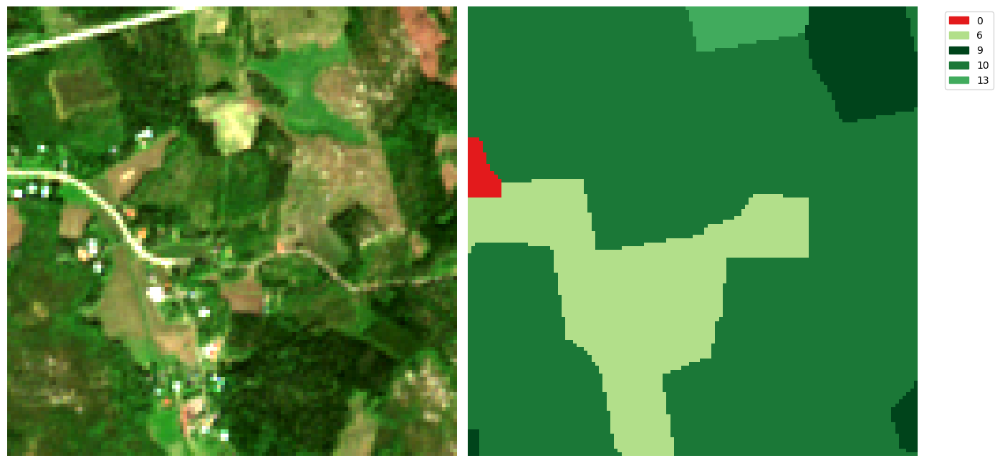

In [ ]:
dataset_name = "reben_7k"

split_file = f"../datasets/splits/{dataset_name}.csv"
ds_rb = ReBEN7kDataset(
    data_dir=f"/mnt/ssd/datasets/reben/BigEarthNet-S2-3%_lmdb", 
    split_file=split_file,
    split="validation",
    keys_path=f"/mnt/ssd/datasets/reben/{dataset_name}_keys.pkl"
)

inspect_data(ds_rb.tiles, ds_rb.masks, split_file)

rgb_img = ds_rb.tiles[4][..., [3, 2, 1]]
plot_images([quant_norm(rgb_img), ds_rb.masks[4]], 
            dataset_name=dataset_name)


# Burn Scars

--- Metadata file info ---
  column names: Index(['patch_id', 'split'], dtype='str')
  unqie value in column `split`: ['train' 'validation' 'test']
    Number of entries in train: 524
    Number of entries in validation: 160
    Number of entries in test: 120

--- Loaded data info ---
  Number of samples loaded: 160
  Tile shape: (512, 512, 6), dtype: int16
  Mask shape: (512, 512), dtype: int8

--- Data Value Ranges ---
  Min = 0.0000, Max = 10000.0000, Mean = 1440.0731

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 274655     (  0.65%)
  Class   0 -> Count: 36530874   ( 87.10%)
  Class   1 -> Count: 5137511    ( 12.25%)


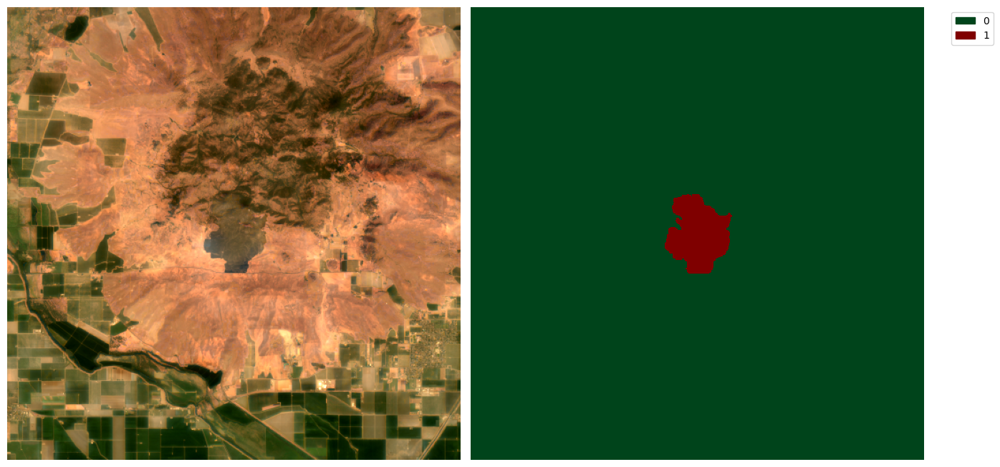

In [ ]:
dataset_name = "burn_scars"

split_file = f"../datasets/splits/{dataset_name}.csv"
ds_bs = BurnScarsDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}",
    split_file=split_file,
    split="validation"
)
inspect_data(ds_bs.tiles, ds_bs.masks, split_file)

rgb_img = ds_bs.tiles[0][..., 2::-1] # B04, B03, B02
plot_images([quant_norm(rgb_img), ds_bs.masks[0]], 
            dataset_name=dataset_name)


# Sen1Floods11

--- Metadata file info ---
  column names: Index(['patch_id', 'split'], dtype='str')
  unqie value in column `split`: <StringArray>
['train', 'validation', 'bolivia_data', 'test']
Length: 4, dtype: str
    Number of entries in train: 252
    Number of entries in validation: 89
    Number of entries in bolivia_data: 15
    Number of entries in test: 90

--- Loaded data info ---
  Number of samples loaded: 86
  Tile shape: (512, 512, 13), dtype: int16
  Mask shape: (512, 512), dtype: int8

--- Data Value Ranges ---
  Min = 0.0000, Max = 11227.0000, Mean = 1632.3310

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 2249659    (  9.98%)
  Class   0 -> Count: 18057120   ( 80.10%)
  Class   1 -> Count: 2237605    (  9.93%)


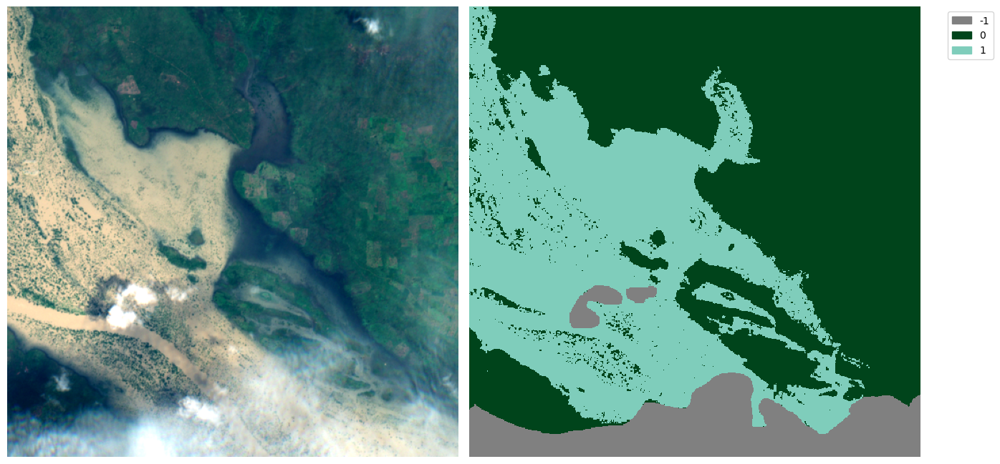

In [7]:
dataset_name = "sen1floods11"

split_file = f"../datasets/splits/{dataset_name}.csv"
ds_sf = Sen1Floods11Dataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}", 
    split_file=split_file,
    split="validation"
)
inspect_data(ds_sf.tiles, ds_sf.masks, split_file)

rgb_img = ds_sf.tiles[0][..., 3:0:-1]
plot_images([quant_norm(rgb_img), ds_sf.masks[0]], 
            dataset_name=dataset_name)


--- Metadata file info ---
  column names: Index(['patch_id', 'split'], dtype='str')
  unqie value in column `split`: <StringArray>
['train', 'validation', 'test']
Length: 3, dtype: str
    Number of entries in train: 1450
    Number of entries in validation: 225
    Number of entries in test: 125

--- Loaded data info ---
  Number of samples loaded: 225
  Tile shape: (256, 256, 13), dtype: float32
  Mask shape: (256, 256), dtype: int8

--- Data Value Ranges ---
  Min = 0.0000, Max = 11900.0000, Mean = 1614.4858

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 271950     (  1.84%)
  Class   0 -> Count: 2026225    ( 13.74%)
  Class   1 -> Count: 3852975    ( 26.13%)
  Class   2 -> Count: 2015925    ( 13.67%)
  Class   3 -> Count: 137775     (  0.93%)
  Class   4 -> Count: 6340125    ( 43.00%)
  Class   5 -> Count: 100625     (  0.68%)


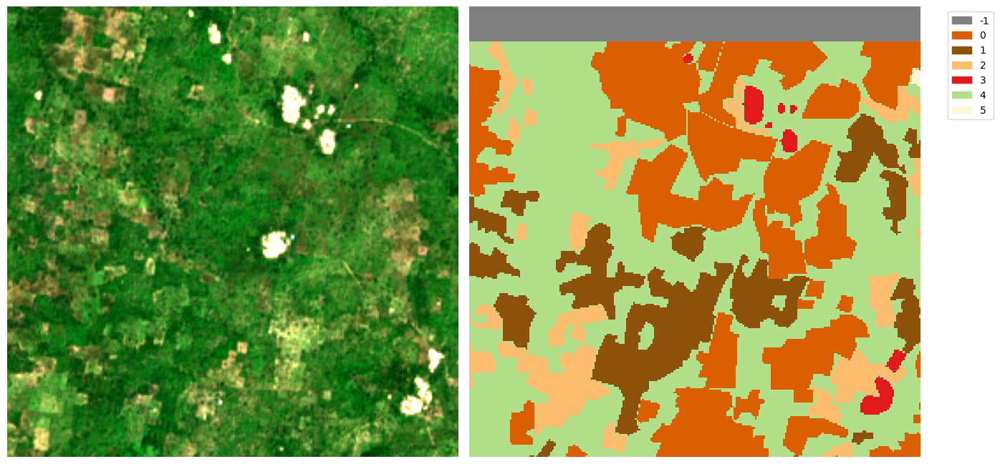

In [27]:
dataset_name = "cashew_plantation"

split_file = f"../datasets/splits/{dataset_name}.csv"
ds_cp = CashewPlantationDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}", 
    split_file=split_file,
    split="validation"
)
inspect_data(ds_cp.tiles, ds_cp.masks, split_file)

rgb_img = ds_cp.tiles[0][..., 3:0:-1]
plot_images([quant_norm(rgb_img), ds_cp.masks[0]], 
            dataset_name=dataset_name)


# C2Seg: Augsburg


--- Loaded data info ---
  Number of samples loaded: 1
  Tile shape: (886, 1360, 4), dtype: int16
  Mask shape: (886, 1360), dtype: int8

--- Data Value Ranges ---
  Min = 0.0000, Max = 7302.0000, Mean = 1284.0652

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 5183       (  0.43%)
  Class   0 -> Count: 21609      (  1.79%)
  Class   1 -> Count: 136073     ( 11.29%)
  Class   2 -> Count: 275532     ( 22.87%)
  Class   3 -> Count: 150511     ( 12.49%)
  Class   4 -> Count: 17247      (  1.43%)
  Class   5 -> Count: 100211     (  8.32%)
  Class   6 -> Count: 277156     ( 23.00%)
  Class   7 -> Count: 2707       (  0.22%)
  Class   8 -> Count: 49519      (  4.11%)
  Class   9 -> Count: 119460     (  9.91%)
  Class  10 -> Count: 43940      (  3.65%)
  Class  11 -> Count: 1101       (  0.09%)
  Class  12 -> Count: 4711       (  0.39%)


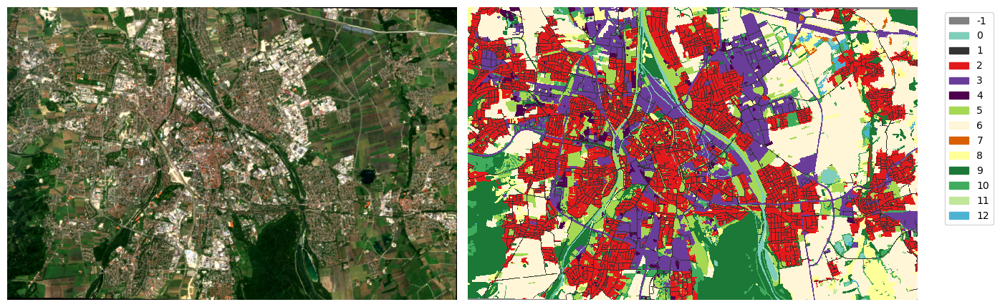

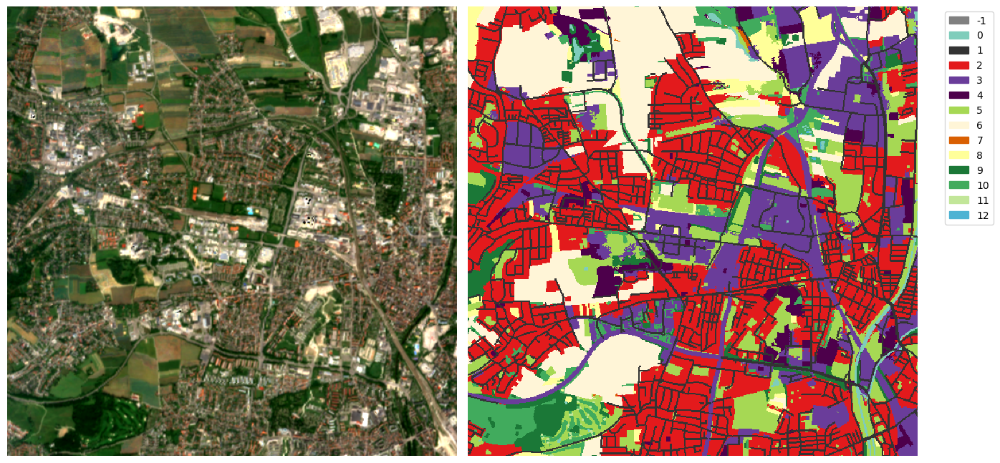

In [ ]:
dataset_name = "c2seg"

city = "augsburg"
ds_c2 = C2SegDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}",
    city=city,
    grid_sampling=False # load whole tile for inspection
)
inspect_data(ds_c2.tiles, ds_c2.masks)

h_crop, w_crop = min(512, ds_c2.tiles[0].shape[0]), min(512, ds_c2.tiles[0].shape[1])

plot_images([quant_norm(ds_c2.tiles[0][..., [2, 1, 0]]), ds_c2.masks[0]], 
            dataset_name=dataset_name)

img_crop = ds_c2.tiles[0][:h_crop, :w_crop, [2, 1, 0]]
mask_crop = ds_c2.masks[0][:h_crop, :w_crop]
plot_images([quant_norm(img_crop), mask_crop], 
            dataset_name=dataset_name)


# C2Seg: Berlin


--- Loaded data info ---
  Number of samples loaded: 1
  Tile shape: (2465, 811, 4), dtype: int16
  Mask shape: (2465, 811), dtype: int8

--- Data Value Ranges ---
  Min = 0.0000, Max = 7707.0000, Mean = 906.3376

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 384800     ( 19.25%)
  Class   0 -> Count: 18375      (  0.92%)
  Class   1 -> Count: 121085     (  6.06%)
  Class   2 -> Count: 525989     ( 26.31%)
  Class   3 -> Count: 191691     (  9.59%)
  Class   4 -> Count: 21745      (  1.09%)
  Class   5 -> Count: 135126     (  6.76%)
  Class   6 -> Count: 190256     (  9.52%)
  Class   7 -> Count: 2704       (  0.14%)
  Class   8 -> Count: 90527      (  4.53%)
  Class   9 -> Count: 210020     ( 10.51%)
  Class  10 -> Count: 99134      (  4.96%)
  Class  11 -> Count: 4622       (  0.23%)
  Class  12 -> Count: 3041       (  0.15%)


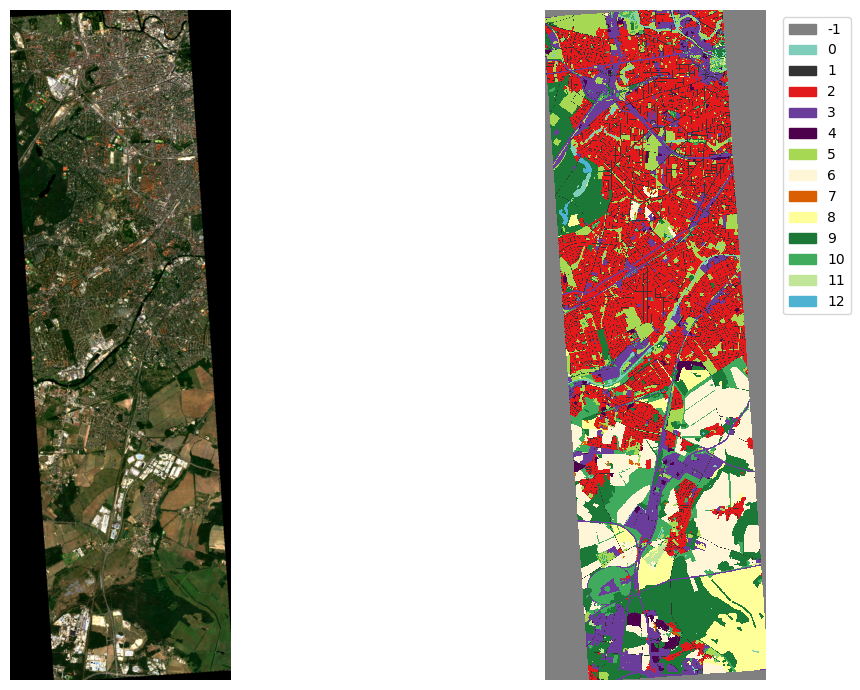

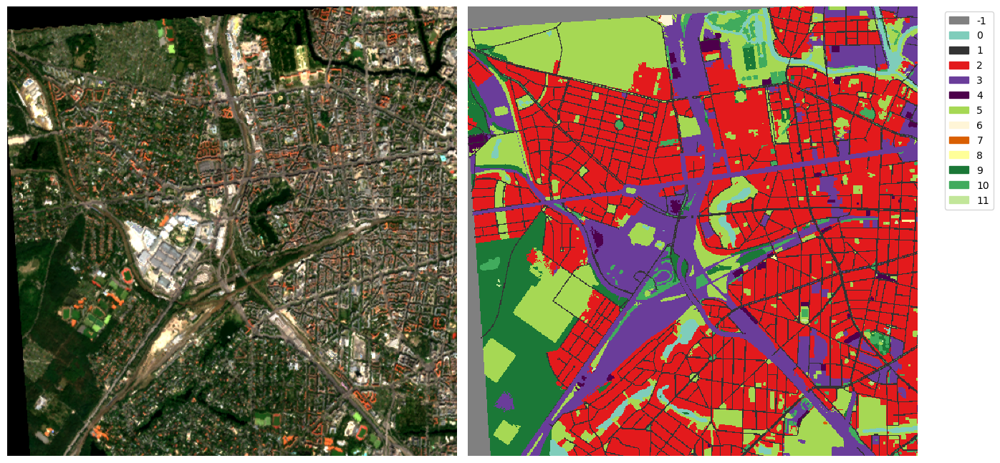

In [ ]:
dataset_name = "c2seg"

city = "berlin"
ds_c2 = C2SegDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}",
    city=city,
    grid_sampling=False # load whole tile for inspection
)
inspect_data(ds_c2.tiles, ds_c2.masks)

h_crop, w_crop = min(512, ds_c2.tiles[0].shape[0]), min(512, ds_c2.tiles[0].shape[1])

plot_images([quant_norm(ds_c2.tiles[0][..., [2, 1, 0]]), ds_c2.masks[0]], 
            dataset_name=dataset_name)

img_crop = ds_c2.tiles[0][:h_crop, :w_crop, [2, 1, 0]]
mask_crop = ds_c2.masks[0][:h_crop, :w_crop]
plot_images([quant_norm(img_crop), mask_crop], 
            dataset_name=dataset_name)


# C2Seg: Beijing


--- Loaded data info ---
  Number of samples loaded: 1
  Tile shape: (13474, 8706, 4), dtype: int16
  Mask shape: (13474, 8706), dtype: int8

--- Data Value Ranges ---
  Min = -1229.0000, Max = 19859.0000, Mean = 792.9607

--- Mask Values & Class Distribution ---
  Class  -1 -> Count: 1771782    (  1.51%)
  Class   0 -> Count: 2300645    (  1.96%)
  Class   1 -> Count: 10653198   (  9.08%)
  Class   2 -> Count: 16499310   ( 14.07%)
  Class   3 -> Count: 7347342    (  6.26%)
  Class   4 -> Count: 4052457    (  3.45%)
  Class   5 -> Count: 12541099   ( 10.69%)
  Class   6 -> Count: 6217906    (  5.30%)
  Class   7 -> Count: 3851609    (  3.28%)
  Class   8 -> Count: 162696     (  0.14%)
  Class   9 -> Count: 49909521   ( 42.55%)
  Class  10 -> Count: 1055948    (  0.90%)
  Class  11 -> Count: 703144     (  0.60%)
  Class  12 -> Count: 237987     (  0.20%)


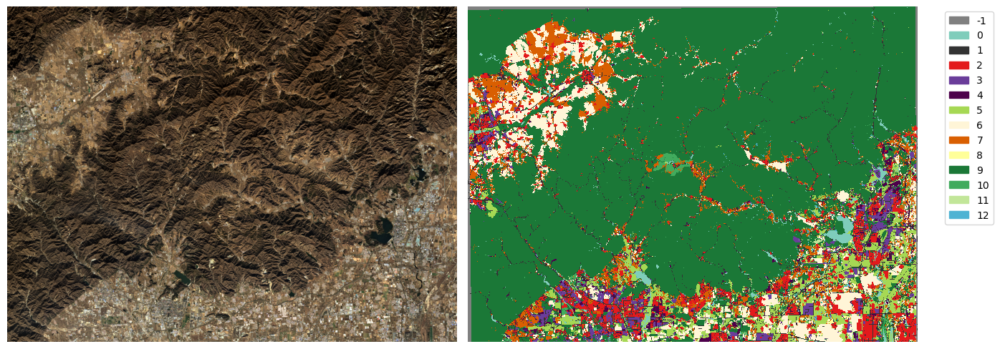

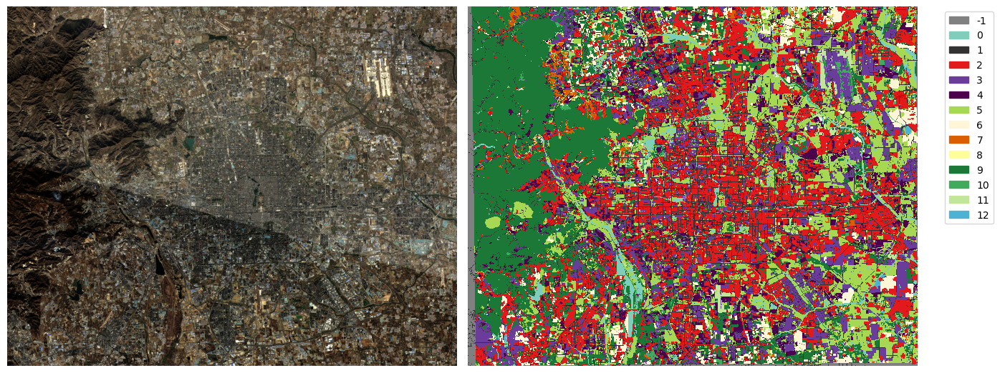

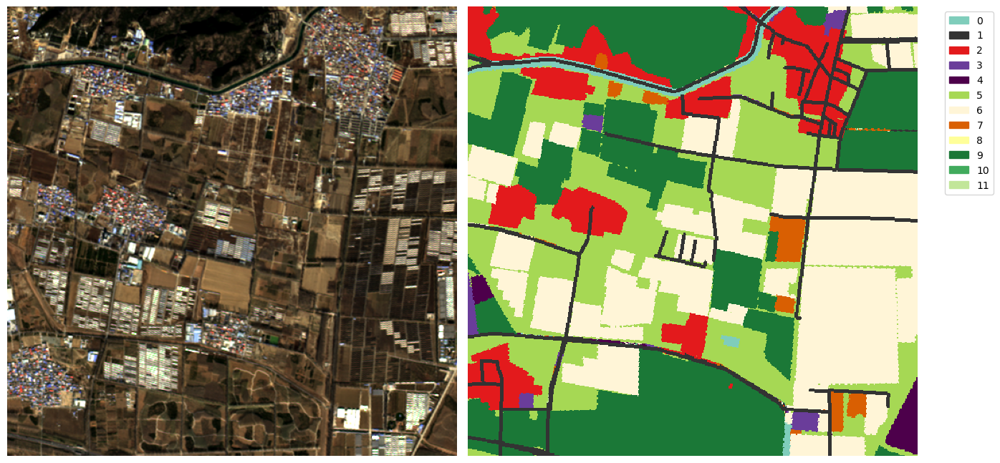

In [3]:
dataset_name = "c2seg"

city = "beijing"
ds_c2 = C2SegDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}",
    city=city,
    grid_sampling=False # load whole tile for inspection
)
inspect_data(ds_c2.tiles, ds_c2.masks)

plot_images([quant_norm(ds_c2.tiles[0][:6500, :, [2, 1, 0]]), ds_c2.masks[0][:6500, :]],
            dataset_name=dataset_name)
plot_images([quant_norm(ds_c2.tiles[0][6500:, :, [2, 1, 0]]), ds_c2.masks[0][6500:, :]],
            dataset_name=dataset_name)

h_crop, w_crop = min(512, ds_c2.tiles[0].shape[0]), min(512, ds_c2.tiles[0].shape[1])
img_crop = ds_c2.tiles[0][6000:6000+h_crop, 4000:4000+w_crop, [2, 1, 0]]
mask_crop = ds_c2.masks[0][6000:6000+h_crop, 4000:4000+w_crop]
plot_images([quant_norm(img_crop), mask_crop], dataset_name=dataset_name)


# C2Seg: Wuhan


--- Loaded data info ---
  Number of samples loaded: 1
  Tile shape: (6225, 8670, 4), dtype: int16
  Mask shape: (6225, 8670), dtype: int8

--- Data Value Ranges ---
  Min = 158.0000, Max = 11705.0000, Mean = 1167.2607

--- Mask Values & Class Distribution ---
  Class   0 -> Count: 14173257   ( 26.26%)
  Class   1 -> Count: 7617479    ( 14.11%)
  Class   2 -> Count: 5044572    (  9.35%)
  Class   3 -> Count: 7072061    ( 13.10%)
  Class   4 -> Count: 192247     (  0.36%)
  Class   5 -> Count: 2191469    (  4.06%)
  Class   6 -> Count: 3124164    (  5.79%)
  Class   7 -> Count: 702523     (  1.30%)
  Class   8 -> Count: 77993      (  0.14%)
  Class   9 -> Count: 6860207    ( 12.71%)
  Class  10 -> Count: 4338656    (  8.04%)
  Class  11 -> Count: 1327537    (  2.46%)
  Class  12 -> Count: 1248585    (  2.31%)


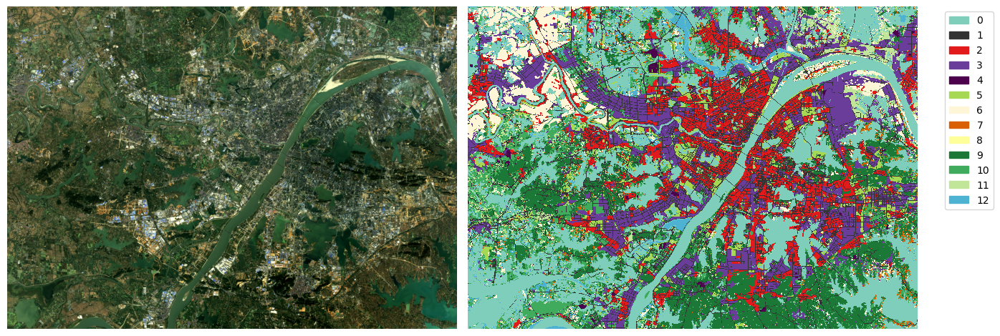

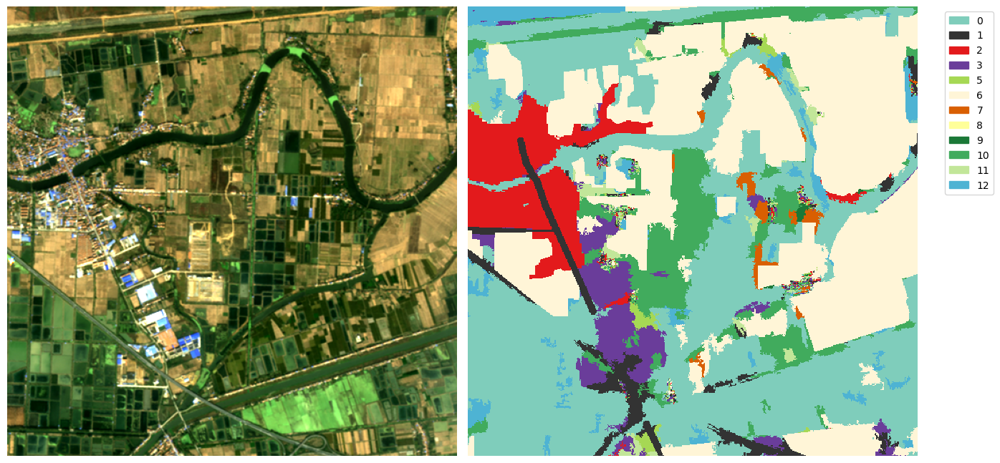

In [ ]:
dataset_name = "c2seg"

city = "wuhan"
ds_c2 = C2SegDataset(
    data_dir=f"/mnt/ssd/datasets/{dataset_name}",
    city=city,
    grid_sampling=False # load whole tile for inspection
)
inspect_data(ds_c2.tiles, ds_c2.masks)

plot_images([quant_norm(ds_c2.tiles[0][..., [2, 1, 0]]), ds_c2.masks[0]], 
            dataset_name=dataset_name)

h_crop, w_crop = min(512, ds_c2.tiles[0].shape[0]), min(512, ds_c2.tiles[0].shape[1])
img_crop = ds_c2.tiles[0][:h_crop, :w_crop, [2, 1, 0]]
mask_crop = ds_c2.masks[0][:h_crop, :w_crop]
plot_images([quant_norm(img_crop), mask_crop], 
            dataset_name=dataset_name)
